In [2]:
# Use my pinned version of astrowidgets
import sys
sys.path.insert(0, "/home/c/czw/notebooks/astrowidgets/build/lib/")
# sys.path
# This should be my ~/notebooks version until DM-56764 merges
from lsst.analysis.tools.actions.plot import FocalPlaneGeometryPlot

In [3]:
import lsst.afw.display as afwDisplay

import numpy as np
import matplotlib.pyplot as plt
from lsst.pipe.base import Struct
from scipy.ndimage import gaussian_filter
from lsst.meas.algorithms import SubtractBackgroundTask
from astropy.table import Table

In [4]:
# Set up butler with the ticket branch obs_lsst
# Set up another to get actual data from.
import lsst.daf.butler as db
butler = db.Butler("main")

In [5]:
#style info:
import matplotlib as mpl

mpl.rcParams.update({
    # Fonts: LaTeX-like, 12 pt to match the body text
    "text.usetex": False,
    "font.family": "serif",
    "font.serif": ["CMU Serif", "cmr10", "Computer Modern Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "cm",
    "axes.formatter.use_mathtext": True,
    "axes.unicode_minus": False,
    "font.size": 12,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "figure.titlesize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 12,
    "legend.title_fontsize": 12,
    "legend.frameon": False,

    # Lines and axes
    "axes.linewidth": 0.6,
    "lines.linewidth": 1.0,

    # Ticks: inward, on all four sides, with minor ticks
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
    "xtick.major.size": 3.5,
    "ytick.major.size": 3.5,
    "xtick.minor.size": 2.0,
    "ytick.minor.size": 2.0,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.minor.width": 0.5,
    "ytick.minor.width": 0.5,

    # Output
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "standard",  # keep the saved PDF at exactly figsize (no tight cropping)
})

# Figure size: single-column width in inches (LaTeX \columnwidth / 72.27)
COLUMN_WIDTH = 3.5
FIG_SIZE = (COLUMN_WIDTH, 0.75 * COLUMN_WIDTH)

# Colorblind-safe (Okabe-Ito) colors used for the linearity plots
GROUP_COLORS = ["#0072B2", "#E69F00", "#8C8C8C", "#009E73", "#CC79A7"]
TURNOFF_COLOR = "#D55E00"

In [6]:
camera = butler.get("camera", instrument='LSSTCam', collections="LSSTCam/calib")

In [7]:
old_exp = 2025060100841
new_exp = 2025120100373

ct_old = butler.get("crosstalk", instrument="LSSTCam", detector=94, exposure=old_exp, collections="LSSTCam/calib")
ct_new = butler.get("crosstalk", instrument="LSSTCam", detector=94, exposure=new_exp, collections="LSSTCam/calib")

In [11]:
new = Table.read("/home/c/czw/stats.20261023/ct_new.fits")
old = Table.read("/home/c/czw/stats.20261023/ct_old.fits")

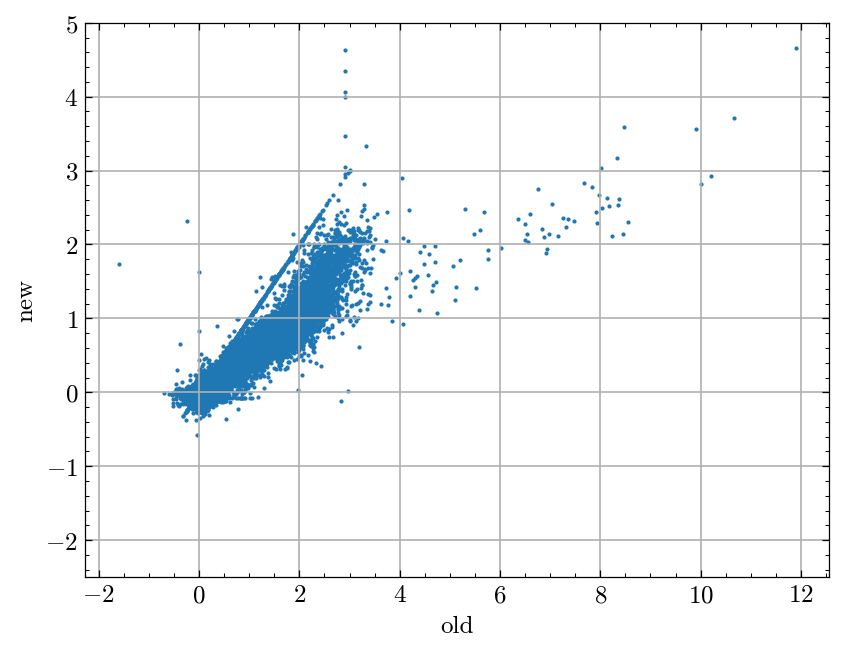

In [12]:
# The x=y line is 
plt.scatter(old['coeff'] * 1e4, new['coeff'] * 1e4, s=1)
plt.xlabel("old")
plt.ylabel("new")
plt.ylim(-2.5, 5)
plt.grid(True)

In [13]:
np.nanpercentile(old['coeff'] / new['coeff'], [0, 25, 50, 75, 100])

/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:4859: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  arr.partition(


--
-0.6586322461081493
0.9581265789780419
2.2840727323786707
--


In [14]:
z = np.ma.array(old['coeff'] - new['coeff'])
y = z.compressed()
np.nanpercentile(y, [0, 25, 50, 75, 100])

array([-3.33318850e-04,  2.45358184e-06,  7.84169056e-06,  1.54062419e-05,
        5.15768546e-03])

In [15]:
tz = old['coeff'] == new['coeff']
# print(new['detector', 'source', 'target', 'coeff'][tz])
# print(old['detector', 'source', 'target', 'coeff'][tz])
print(sorted(set(old['detector'][tz])))

[np.int64(27), np.int64(189), np.int64(190), np.int64(193), np.int64(194), np.int64(197), np.int64(198), np.int64(201), np.int64(202)]


In [16]:
counts = {
    "detector": [],
    "amplifier": [],
    "z": [],
}

for det in camera:
    detId = det.getId()
    if detId == 122:
        continue
    if "_G" in det.getPhysicalType():
        continue
    for amp in det:
        ampName = amp.getName()
        z = new[new["detector"] == detId]
        zz = z[z["source"] == ampName]
        counts['detector'].append(detId)
        counts['amplifier'].append(ampName)
        counts['z'].append(max(zz["nPix"]))
ctab = Table(counts)

In [17]:
np.nanpercentile(ctab['z'].transpose(), [0, 5, 25, 50, 75, 95, 100])

0.0
262146.60000000003
614386.75
889369.0
1088136.5
1253837.65
3144729.0


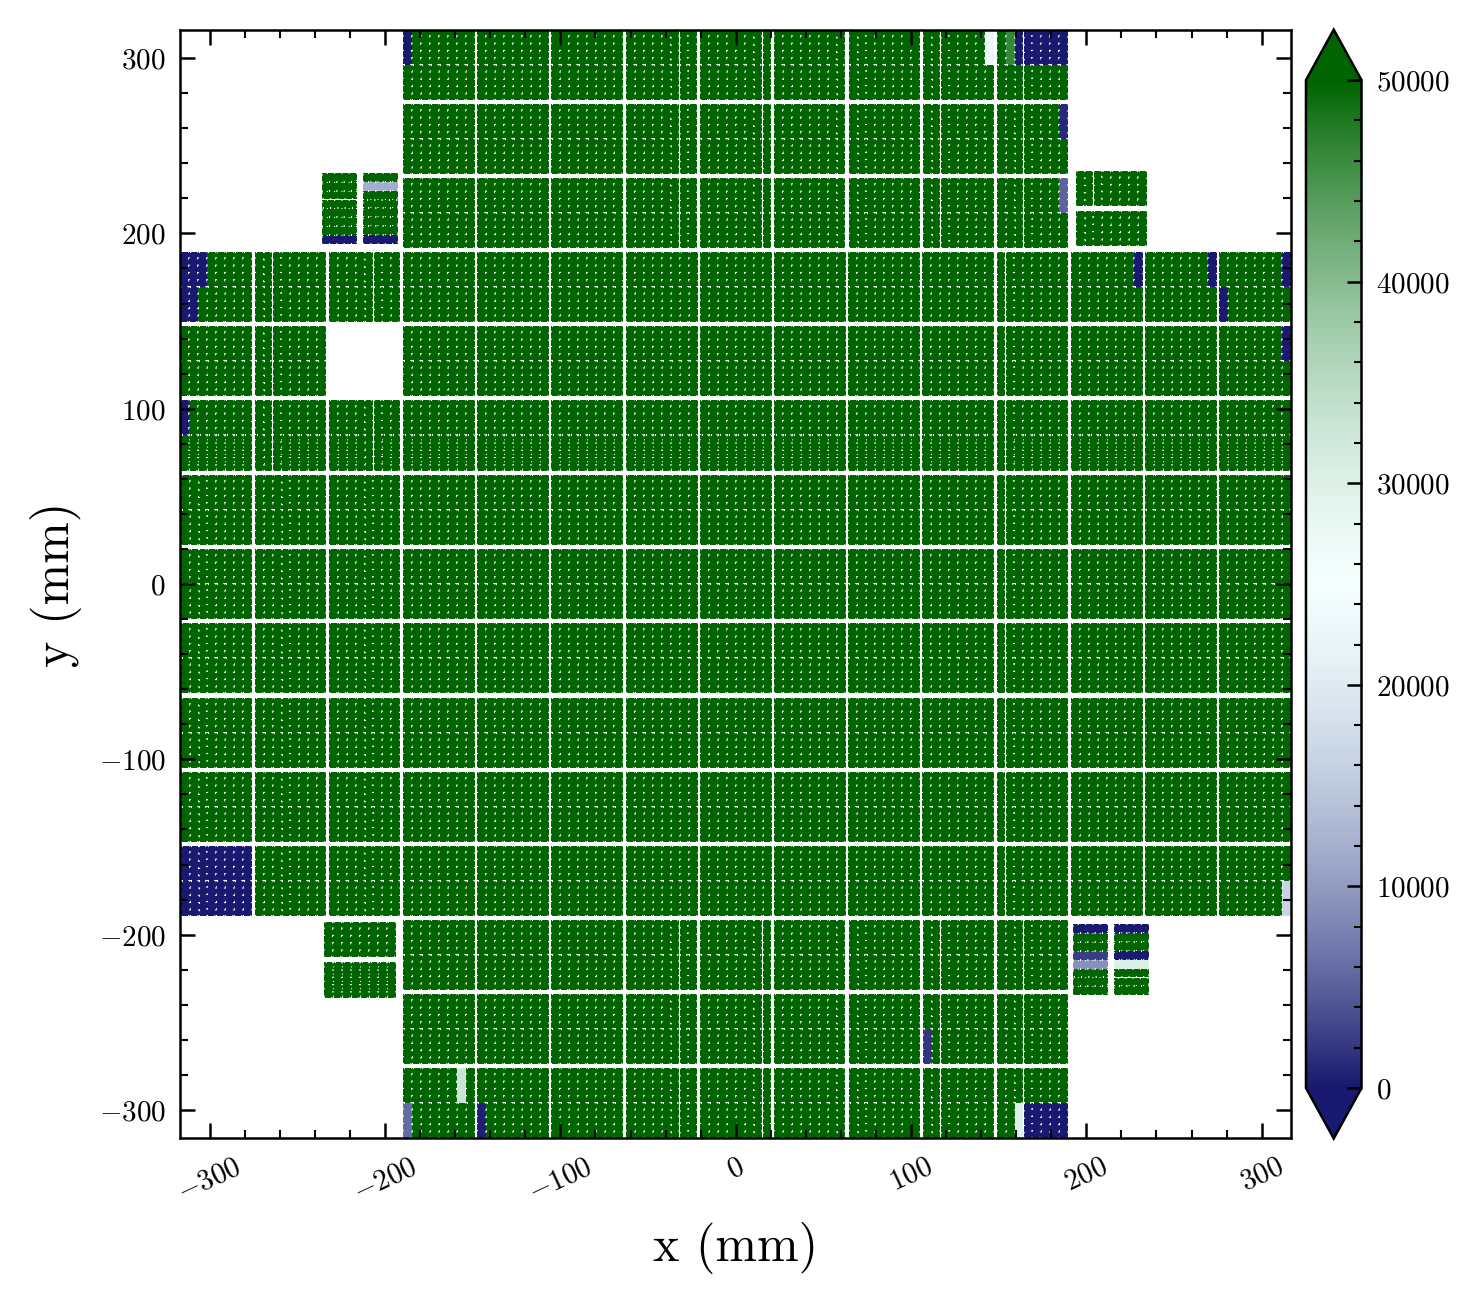

In [18]:
npix = FocalPlaneGeometryPlot(
    plotMin=0.0, plotMax=50_000.0, showStats=False,
).makePlot(
    data=ctab, camera=camera,
    cmap=["cornflowerblue", "lightcyan", "darkorange"],
)
npix.savefig("./rtn117-crosstalk_npix.png")

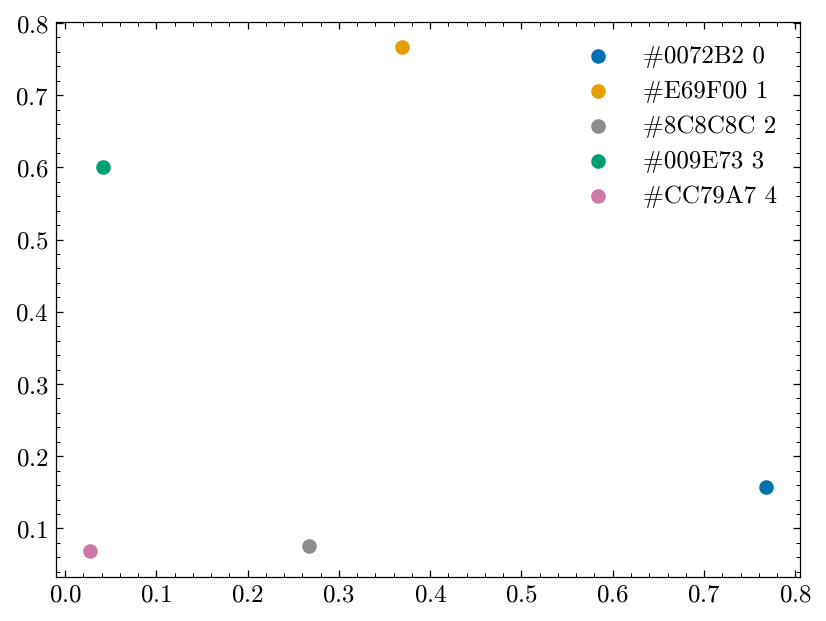

In [19]:
ii = 0
for cc in GROUP_COLORS:
    plt.scatter(np.random.rand(), np.random.rand(),
                c=cc, label=f"{cc} {ii}")
    ii += 1
plt.legend()
plt.show()

In [20]:
no_corr_coll = 'u/czw/DM-51599x/ct_quality/sciProc-non.20261016'
lin_corr_coll = 'u/czw/DM-51599x/ct_quality/sciProc.20261016'
full_corr_coll = 'u/czw/DM-51599x/ct_quality/sciProc-reg.20261016'

In [21]:
expIds = (2025080700292, 2025080700300, 2025082000312, 2025082000137)
detIds = (15, 23, 94, 133)

minmax = {
    2025080700292: {
        15: (1300, 2050), 23: (1000, 1750), 94: (500, 1250), 133: (1800, 2550)},
    2025082000312: {
        15: (200, 950), 23: (1, 100), 94: (400, 1150), 133: (500, 1250)},
    2025080700300: {
        15: (1300, 2050), 23: (1000, 1750), 94: (500, 1250), 133: (1800, 2550)},
    2025082000137: {
        15: (1800, 2550), 23: (1, 100), 94: (2000, 2750), 133: (2000, 2750)},
}

In [22]:
ei = 1
di = 1
no_im = butler.get("post_isr_image", instrument="LSSTCam", exposure=expIds[ei], 
                   detector=detIds[di], collections=no_corr_coll)
lin_im = butler.get("post_isr_image", instrument="LSSTCam", exposure=expIds[ei], 
                   detector=detIds[di], collections=lin_corr_coll)
full_im = butler.get("post_isr_image", instrument="LSSTCam", exposure=expIds[ei], 
                   detector=detIds[di], collections=full_corr_coll)
detector = camera[detIds[di]]

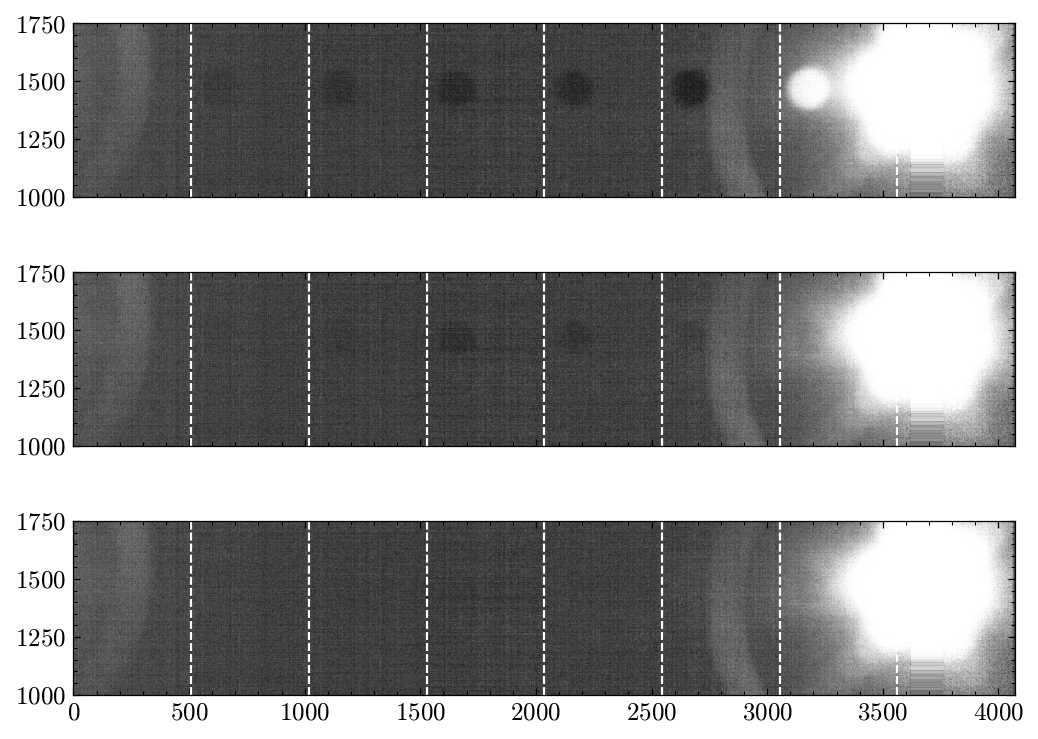

In [30]:
plt.rcParams.update({"font.size": 12})

vmin=0
vmax=50

ymin,ymax = minmax[expIds[ei]][detIds[di]]
cmap_name = "grey"

fig = plt.figure(figsize=(7.1, 5.3))
axes = fig.subplots(3, 1, sharex=True)
axes[0].imshow(no_im.image.array, origin="lower", 
               vmin=vmin, vmax=vmax,  cmap=mpl.colormaps[cmap_name])
axes[1].imshow(lin_im.image.array, origin="lower", 
               vmin=vmin, vmax=vmax, cmap=mpl.colormaps[cmap_name])
im = axes[2].imshow(full_im.image.array, origin="lower", 
               vmin=vmin, vmax=vmax, cmap=mpl.colormaps[cmap_name])

for amp in detector:
    ll = amp.getBBox().getMinX()
    for axnum in (0, 1, 2):
        axes[axnum].vlines(ll, ymin, ymax, colors="white", linestyle="--")

axes[0].set_ylim(ymin, ymax)
axes[1].set_ylim(ymin, ymax)
axes[2].set_ylim(ymin, ymax)

fig.tight_layout() #rect=(0, 0, 0.9, 1))
# fig.canvas.draw()
# top = axes[0].get_position()
# bottom = axes[2].get_position()
# cax = fig.add_axes([bottom.x1 + 0.02, bottom.y0, 0.02, top.y1 - bottom.y0])
#fig.colorbar(im, cax=cax)

fig.savefig("./rtn117-crosstalk_application.png")
fig.show()

In [ ]:
np.sum(full_im.mask.array & 2**11) / 2**11


In [ ]:
plt.plot(np.median(full_im.image.array[1480:1520, :], axis=0))
plt.plot(np.median(lin_im.image.array[1480:1520, :], axis=0))
# plt.plot(np.median(no_im.image.array[1480:1520, :], axis=0))
plt.hlines([5, 8, 13.46], 0, 4000, color='r')
# plt.yscale("symlog")
plt.ylim(1, 100)

In [ ]:
np.median(no_im.image.array)

In [ ]:
types = {'ITL': [], 'E2V': []}
for det in camera:
    if (det.getId() < 189):
        print(det.getId(), det.getPhysicalType())
        types[det.getPhysicalType()].append(det.getId())

In [ ]:
types

In [ ]:
set(types["ITL"])